# Contrasting successful transport with failure

## A Generated Design with a Known Modifier

Generated observations are needed because the public panel does not reveal both potential outcomes or a true target effect. Let $G_i\in\{0,1,2,3\}$ be a known effect modifier. The stratum effect is

$$
\tau(g)=0.2+0.4g.
$$

Within each source pair, both members share the same untreated potential outcome. One member is randomly assigned treatment and the other control. Their potential outcomes are

$$
Y_{ig}(0)=m_g+\varepsilon_{ig},\qquad Y_{ig}(1)=Y_{ig}(0)+\tau(g).
$$

Here, $m_g=-0.3+0.25g$ is the stratum baseline, and $\varepsilon_{ig}$ is a generated pair-level disturbance. The paired construction makes the treated-control difference exactly $\tau(g)$ in every source stratum. If $\pi_g^T$ is the generated target share, the known target effect is

$$
\tau^T=\sum_{g=0}^{3}\pi_g^T\tau(g).
$$

The random state is fixed at 6603. The source and target compositions differ by design, so omitting $G_i$ changes the target calculation.

### Notebook setup

#### Packages and notebook settings

In [ ]:
from pathlib import Path as _FigurePath
from sys import path as _figure_import_path

_figure_folder = _FigurePath.cwd()
_figure_root = next(
    folder for folder in (_figure_folder, *_figure_folder.parents)
    if (folder / "notebook_figures.py").is_file()
)
_figure_import_path.insert(0, str(_figure_root))
from notebook_figures import display_notebook_figure

from pathlib import Path
import sys
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import HTML, display as _display

def display(value):
    module = value.__class__.__module__
    if module.startswith('pandas') and hasattr(value, '_repr_html_'):
        html = value._repr_html_()
        return _display(HTML('<div style="display:flex;justify-content:center;">' + html + '</div>'))
    return _display(value)
BOOK_ROOT = Path.cwd().parents[1]
if str(BOOK_ROOT) not in sys.path:
    sys.path.insert(0, str(BOOK_ROOT))
from book_support import ensure_dataset
FINANCIAL_ROOT = BOOK_ROOT
import RiskLabAI
from RiskLabAI.causal_factor_analysis import transported_ate
assert RiskLabAI.__version__ == '3.2.0'
FIGURES = BOOK_ROOT / 'outputs' / 'figures' / '06_transportability'
TABLES = BOOK_ROOT / 'outputs' / 'tables' / '06_transportability'
FIGURE_DATA = BOOK_ROOT / 'outputs' / 'figure_data' / '06_transportability'


#### Figure settings

In [ ]:
DATA_FILE = ensure_dataset(BOOK_ROOT, 'mpdta')
for directory in [FIGURES, TABLES, FIGURE_DATA]:
    directory.mkdir(parents=True, exist_ok=True)
PALETTE = {'background': '#111827', 'axes': '#111827', 'text': '#E5E7EB', 'cyan': '#38BDF8', 'amber': '#FBBF24', 'green': '#34D399', 'rose': '#FB7185', 'violet': '#C084FC', 'grid': '#374151'}
plt.rcParams.update({'font.family': 'DejaVu Serif', 'font.size': 11.5, 'figure.facecolor': PALETTE['background'], 'axes.facecolor': PALETTE['axes'], 'axes.edgecolor': PALETTE['text'], 'axes.labelcolor': PALETTE['text'], 'axes.titlecolor': PALETTE['text'], 'xtick.color': PALETTE['text'], 'ytick.color': PALETTE['text'], 'text.color': PALETTE['text'], 'grid.color': PALETTE['grid'], 'grid.linestyle': ':', 'legend.facecolor': PALETTE['axes'], 'legend.edgecolor': PALETTE['grid'], 'savefig.facecolor': PALETTE['background'], 'savefig.transparent': False, 'savefig.dpi': 300})

def rendered_value(value):
    if pd.isna(value):
        return ''
    if isinstance(value, (bool, np.bool_)):
        return 'Pass' if bool(value) else 'Fail'
    if isinstance(value, (int, np.integer)):
        return f'{int(value):,}'
    if isinstance(value, (float, np.floating)):
        value = float(value)
        if value == 0:
            return '0'
        if value.is_integer():
            return f'{int(value):,}'
        if abs(value) < 0.0001 or abs(value) >= 1000000:
            return f'{value:.6g}'
        return f'{value:.6f}'.rstrip('0').rstrip('.')
    return str(value)



#### Table and figure formatting

In [ ]:
def rendered_frame(frame):
    return frame.apply(lambda column: column.map(rendered_value))

def save_table(frame, stem, caption, label, fit=False):
    shown = rendered_frame(frame)
    shown.to_csv(TABLES / f'{stem}.csv', index=False)
    latex = shown.to_latex(index=False, escape=True, caption=caption, label=label, position='htbp')
    latex = latex.replace('\\begin{table}[htbp]', '\\begin{table}[htbp]\n\\centering', 1)
    if fit:
        latex = latex.replace('\\begin{tabular}', '\\begin{adjustbox}{max width=\\textwidth}\\begin{tabular}', 1).replace('\\end{tabular}', '\\end{tabular}\\end{adjustbox}', 1)
    (TABLES / f'{stem}.tex').write_text(latex, encoding='utf-8')
    display(shown)
    return shown

def finish_axis(axis, grid=True):
    axis.spines['top'].set_visible(False)
    axis.spines['right'].set_visible(False)
    if grid:
        axis.grid(True, alpha=0.65)
    axis.set_axisbelow(True)

def save_figure(figure, stem):
    figure.savefig(FIGURES / f'{stem}.png', dpi=300, bbox_inches='tight', facecolor=PALETTE['background'], transparent=False)
    figure.savefig(FIGURES / f'{stem}.pdf', bbox_inches='tight', facecolor=PALETTE['background'], transparent=False)
    display_notebook_figure(figure)
    plt.close(figure)



### County frame

In [ ]:
def county_frame():
    raw = pd.read_csv(DATA_FILE)
    employment = raw.pivot(index='countyreal', columns='year', values='lemp')
    population = raw.pivot(index='countyreal', columns='year', values='lpop')
    first_treatment = raw.groupby('countyreal')['first_treat'].first()
    frame = pd.DataFrame({'County identifier': employment.index.to_numpy(), 'Treatment group': (first_treatment.reindex(employment.index).to_numpy() > 0).astype(int), 'Log employment in 2003': employment[2003].to_numpy(), 'Log employment in 2007': employment[2007].to_numpy(), 'Log population in 2003': population[2003].to_numpy()})
    frame['Employment change, 2003 to 2007'] = frame['Log employment in 2007'] - frame['Log employment in 2003']
    population_median = float(frame['Log population in 2003'].median())
    frame['Domain'] = np.where(frame['Log population in 2003'] <= population_median, 'Source', 'Target')
    frame['Stratum'] = pd.qcut(frame['Log employment in 2003'], 3, labels=False, duplicates='drop').astype(int)
    frame['Stratum name'] = frame['Stratum'].map({0: 'Low baseline employment', 1: 'Middle baseline employment', 2: 'High baseline employment'})
    return (raw, frame, population_median)

def transport_summary(frame, stratum_column):
    strata = sorted(frame[stratum_column].dropna().unique())
    source = frame[frame['Domain'] == 'Source']
    target = frame[frame['Domain'] == 'Target']
    source_counts = pd.crosstab(source[stratum_column], source['Treatment group']).reindex(index=strata, columns=[0, 1], fill_value=0)
    source_means = source.groupby([stratum_column, 'Treatment group'])['Employment change, 2003 to 2007'].mean().unstack().reindex(index=strata, columns=[0, 1])
    source_sizes = source[stratum_column].value_counts().reindex(strata, fill_value=0)
    target_sizes = target[stratum_column].value_counts().reindex(strata, fill_value=0)
    result = pd.DataFrame({'Stratum': strata, 'Source control count': source_counts[0].to_numpy(), 'Source treated count': source_counts[1].to_numpy(), 'Source control mean': source_means[0].to_numpy(), 'Source treated mean': source_means[1].to_numpy(), 'Source contrast': (source_means[1] - source_means[0]).to_numpy(), 'Source probability': (source_sizes / source_sizes.sum()).to_numpy(), 'Target count': target_sizes.to_numpy(), 'Target probability': (target_sizes / target_sizes.sum()).to_numpy()})
    return result

def capture_failure(name, calculation):
    try:
        calculation()
        return {'Check': name, 'Rejected': False, 'Message': 'No error'}
    except ValueError as error:
        return {'Check': name, 'Rejected': True, 'Message': str(error)}


### Declared design for the generated transport experiment

In [1]:
random_state = 6603
rng = np.random.default_rng(random_state)
source_pair_counts = np.array([400, 300, 200, 100])
target_counts = np.array([150, 300, 450, 600])
strata = np.arange(4)
true_effects = 0.2 + 0.4 * strata
source_rows = []
for stratum, pair_count in zip(strata, source_pair_counts):
    baselines = -0.3 + 0.25 * stratum + rng.normal(0, 0.2, pair_count)
    orientations = rng.integers(0, 2, pair_count)
    for pair_identifier, (baseline, orientation) in enumerate(zip(baselines, orientations)):
        for member in [0, 1]:
            treatment = int(orientation if member == 0 else 1 - orientation)
            source_rows.append({'Stratum': int(stratum), 'Pair': int(pair_identifier), 'Treatment': treatment, 'Untreated potential outcome': float(baseline), 'Treated potential outcome': float(baseline + true_effects[stratum]), 'Observed outcome': float(baseline + treatment * true_effects[stratum])})
source_generated = pd.DataFrame(source_rows)
target_rows = []
for stratum, target_count in zip(strata, target_counts):
    baselines = -0.3 + 0.25 * stratum + rng.normal(0, 0.2, target_count)
    for baseline in baselines:
        target_rows.append({'Stratum': int(stratum), 'Untreated potential outcome': float(baseline), 'Treated potential outcome': float(baseline + true_effects[stratum])})
target_generated = pd.DataFrame(target_rows)
source_means = source_generated.groupby(['Stratum', 'Treatment'])['Observed outcome'].mean().unstack().reindex(strata)
source_counts = pd.crosstab(source_generated['Stratum'], source_generated['Treatment']).reindex(index=strata, columns=[0, 1], fill_value=0)
target_probabilities = target_generated['Stratum'].value_counts(normalize=True).reindex(strata).to_numpy()
source_probabilities = source_generated['Stratum'].value_counts(normalize=True).reindex(strata).to_numpy()
recovered_effects = (source_means[1] - source_means[0]).to_numpy()
transported = transported_ate(source_means[1], source_means[0], target_probabilities, source_counts[1], source_counts[0])
known_target_effect = float(target_probabilities @ true_effects)
known_source_effect = float(source_probabilities @ true_effects)
assert np.allclose(recovered_effects, true_effects)
assert np.isclose(transported, known_target_effect)
design = pd.DataFrame([{'Parameter': 'Random state', 'Value': random_state}, {'Parameter': 'Source pairs', 'Value': int(source_pair_counts.sum())}, {'Parameter': 'Source observations', 'Value': len(source_generated)}, {'Parameter': 'Target observations', 'Value': len(target_generated)}, {'Parameter': 'Modifier strata', 'Value': len(strata)}, {'Parameter': 'Known source effect', 'Value': known_source_effect}, {'Parameter': 'Known target effect', 'Value': known_target_effect}])
save_table(design, 'recovery_generated_design', 'Declared design for the generated transport experiment.', 'tab:cim6-recovery-design');


,Parameter,Value
0,Random state,"6,603"
1,Source pairs,"1,000"
2,Source observations,"2,000"
3,Target observations,"1,500"
4,Modifier strata,4
5,Known source effect,0.6
6,Known target effect,1


### Scope of the generated transport experiment

,Item,Value
0,Reason generated data are necessary,Both potential outcomes and the true target ef...
1,Treatment assignment,One randomized treated member and one control ...
2,Effect modifier,Four-level observed stratum
3,Generated market claim,None
4,Download during execution,None


,Stratum,Source probability,Target probability,True stratum effect
0,0,0.4,0.1,0.2
1,1,0.3,0.2,0.6
2,2,0.2,0.3,1
3,3,0.1,0.4,1.4


,Stratum,Source control count,Source treated count,True effect,Recovered effect,Recovery error
0,0,400,400,0.2,0.2,0
1,1,300,300,0.6,0.6,0
2,2,200,200,1,1,-1.11022e-16
3,3,100,100,1.4,1.4,2.22045e-16


,Quantity,Value
0,Known target effect,1
1,Transported estimate,1
2,Recovery error,0


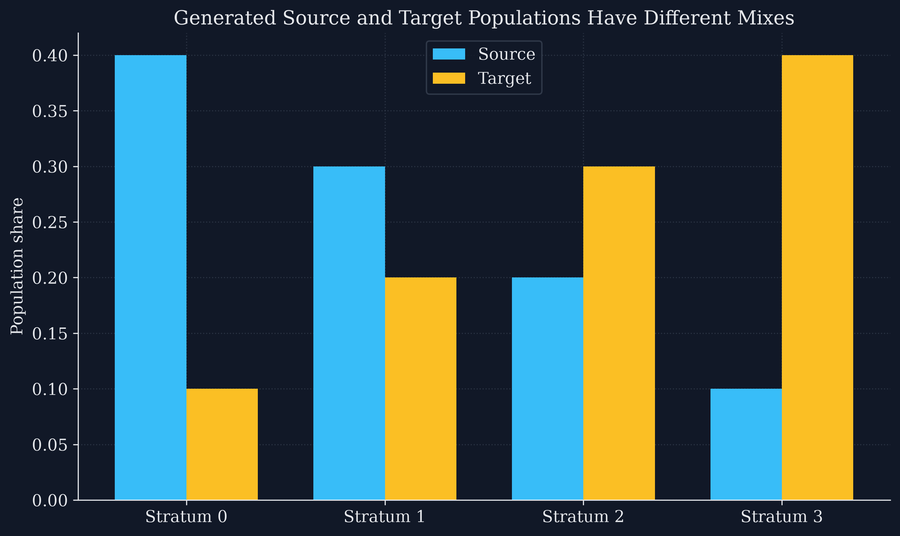

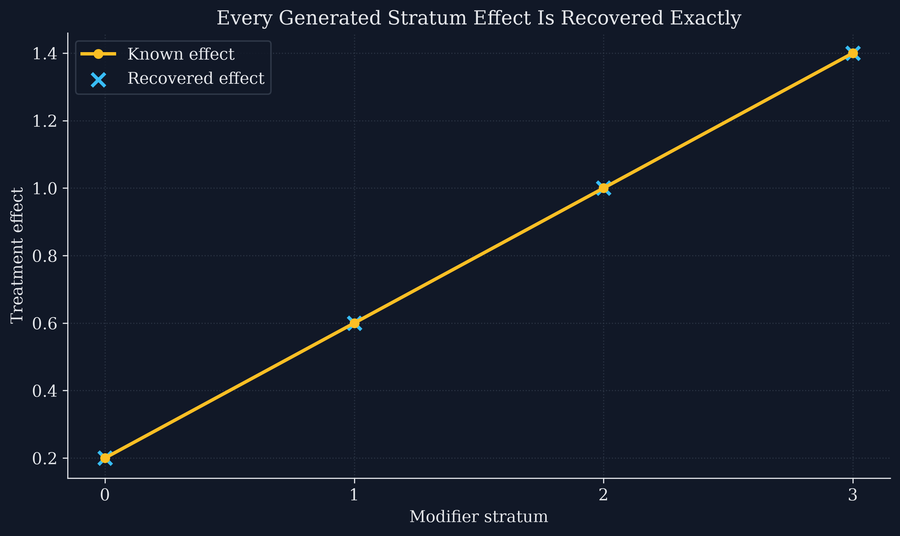

In [1]:
generated_contract = pd.DataFrame([{'Item': 'Reason generated data are necessary', 'Value': 'Both potential outcomes and the true target effect must be known'}, {'Item': 'Treatment assignment', 'Value': 'One randomized treated member and one control member within every source pair'}, {'Item': 'Effect modifier', 'Value': 'Four-level observed stratum'}, {'Item': 'Generated market claim', 'Value': 'None'}, {'Item': 'Download during execution', 'Value': 'None'}])
save_table(generated_contract, 'recovery_generated_contract', 'Scope of the generated transport experiment.', 'tab:cim6-recovery-contract', fit=True)
weight_table = pd.DataFrame({'Stratum': strata, 'Source probability': source_probabilities, 'Target probability': target_probabilities, 'True stratum effect': true_effects})
save_table(weight_table, 'recovery_domain_weights', 'Generated source and target stratum weights.', 'tab:cim6-recovery-domain-weights')
stratum_recovery = pd.DataFrame({'Stratum': strata, 'Source control count': source_counts[0].to_numpy(), 'Source treated count': source_counts[1].to_numpy(), 'True effect': true_effects, 'Recovered effect': recovered_effects, 'Recovery error': recovered_effects - true_effects})
save_table(stratum_recovery, 'recovery_stratum_effects', 'Known and recovered effects in each generated stratum.', 'tab:cim6-recovery-stratum-effects', fit=True)
primary_recovery = pd.DataFrame([{'Quantity': 'Known target effect', 'Value': known_target_effect}, {'Quantity': 'Transported estimate', 'Value': transported}, {'Quantity': 'Recovery error', 'Value': transported - known_target_effect}])
save_table(primary_recovery, 'recovery_primary_check', 'Exact known-truth recovery in the generated design.', 'tab:cim6-recovery-primary-check')
weight_table.to_csv(FIGURE_DATA / 'recovery_domain_weights.csv', index=False)
positions = np.arange(len(strata))
figure, axis = plt.subplots(figsize=(8.8, 5.2), constrained_layout=True)
width = 0.36
axis.bar(positions - width / 2, source_probabilities, width, color=PALETTE['cyan'], label='Source')
axis.bar(positions + width / 2, target_probabilities, width, color=PALETTE['amber'], label='Target')
axis.set_xticks(positions, [f'Stratum {value}' for value in strata])
axis.set_ylabel('Population share')
axis.set_title('Generated Source and Target Populations Have Different Mixes')
axis.legend()
finish_axis(axis)
save_figure(figure, 'recovery_domain_weights')
stratum_recovery.to_csv(FIGURE_DATA / 'recovery_stratum_effects.csv', index=False)
figure, axis = plt.subplots(figsize=(8.8, 5.2), constrained_layout=True)
axis.plot(strata, true_effects, color=PALETTE['amber'], marker='o', linewidth=2.4, label='Known effect')
axis.scatter(strata, recovered_effects, color=PALETTE['cyan'], marker='x', s=90, linewidths=2.4, label='Recovered effect')
axis.set_xticks(strata)
axis.set_xlabel('Modifier stratum')
axis.set_ylabel('Treatment effect')
axis.set_title('Every Generated Stratum Effect Is Recovered Exactly')
axis.legend()
finish_axis(axis)
save_figure(figure, 'recovery_stratum_effects')


## How an omitted modifier changes the target mix

If the modifier is omitted, the calculation uses the source mixture of stratum effects. In this design that value is

$$
\tau^{S}=\sum_{g=0}^{3}\pi_g^S\tau(g),
$$

where $\pi_g^S$ is the source probability of stratum $g$. The true target value instead uses $\pi_g^T$. Their difference is specific to the declared design; it is not a general direction of bias.

A coarsened modifier combines adjacent strata. The source effect within each combined group then depends on the source composition inside that group. If the target has a different internal composition, coarse standardization need not recover the target truth.

### Generated estimates under correct, coarsened, and omitted modifiers

In [2]:
omitted_modifier = transported_ate(
    [source_generated[source_generated["Treatment"] == 1]["Observed outcome"].mean()],
    [source_generated[source_generated["Treatment"] == 0]["Observed outcome"].mean()],
    [1.0],
    [int((source_generated["Treatment"] == 1).sum())],
    [int((source_generated["Treatment"] == 0).sum())],
)

source_generated["Coarse stratum"] = (source_generated["Stratum"] >= 2).astype(int)
target_generated["Coarse stratum"] = (target_generated["Stratum"] >= 2).astype(int)
coarse_means = source_generated.groupby(["Coarse stratum", "Treatment"])["Observed outcome"].mean().unstack().reindex([0, 1])
coarse_counts = pd.crosstab(source_generated["Coarse stratum"], source_generated["Treatment"]).reindex(index=[0, 1], columns=[0, 1], fill_value=0)
coarse_target_probabilities = target_generated["Coarse stratum"].value_counts(normalize=True).reindex([0, 1]).to_numpy()
coarse_transport = transported_ate(coarse_means[1], coarse_means[0], coarse_target_probabilities, coarse_counts[1], coarse_counts[0])

comparison = pd.DataFrame([
    {"Calculation": "Known target effect", "Estimate": known_target_effect, "Error from target truth": 0},
    {"Calculation": "Four-stratum transport", "Estimate": transported, "Error from target truth": transported - known_target_effect},
    {"Calculation": "Two-stratum coarse transport", "Estimate": coarse_transport, "Error from target truth": coarse_transport - known_target_effect},
    {"Calculation": "Modifier omitted", "Estimate": omitted_modifier, "Error from target truth": omitted_modifier - known_target_effect},
    {"Calculation": "Known source effect", "Estimate": known_source_effect, "Error from target truth": known_source_effect - known_target_effect},
])
save_table(comparison, "recovery_estimate_comparison", "Generated estimates under correct, coarsened, and omitted modifiers.", "tab:cim6-recovery-comparison", fit=True)

coarse_details = pd.DataFrame({
    "Coarse stratum": [0, 1],
    "Source control count": coarse_counts[0].to_numpy(),
    "Source treated count": coarse_counts[1].to_numpy(),
    "Source contrast": (coarse_means[1] - coarse_means[0]).to_numpy(),
    "Target probability": coarse_target_probabilities,
})
save_table(coarse_details, "recovery_coarse_strata", "Coarsened modifier calculation in the generated design.", "tab:cim6-recovery-coarse-strata", fit=True);



,Calculation,Estimate,Error from target truth
0,Known target effect,1,0
1,Four-stratum transport,1,0
2,Two-stratum coarse transport,0.904762,-0.095238
3,Modifier omitted,0.6,-0.4
4,Known source effect,0.6,-0.4


,Coarse stratum,Source control count,Source treated count,Source contrast,Target probability
0,0,700,700,0.371429,0.3
1,1,300,300,1.133333,0.7


### Generated truth and estimates as the target composition changes

In [2]:
mix_rows = []
for mixing_weight in np.linspace(0, 1, 21):
    weights = (1 - mixing_weight) * source_probabilities + mixing_weight * target_probabilities
    true_value = float(weights @ true_effects)
    coarse_weights = np.array([weights[:2].sum(), weights[2:].sum()])
    coarse_value = float(coarse_weights @ (coarse_means[1] - coarse_means[0]).to_numpy())
    mix_rows.append({
        "Target mixing weight": mixing_weight,
        "Known effect": true_value,
        "Four-stratum estimate": float(weights @ recovered_effects),
        "Two-stratum estimate": coarse_value,
        "Omitted-modifier estimate": omitted_modifier,
    })
mix_path = pd.DataFrame(mix_rows)
mix_path["Four-stratum error"] = mix_path["Four-stratum estimate"] - mix_path["Known effect"]
mix_path["Two-stratum error"] = mix_path["Two-stratum estimate"] - mix_path["Known effect"]
mix_path["Omitted-modifier error"] = mix_path["Omitted-modifier estimate"] - mix_path["Known effect"]
save_table(mix_path, "recovery_target_mix_path", "Generated truth and estimates as the target composition changes.", "tab:cim6-recovery-target-mix-path", fit=True)
save_table(mix_path.iloc[[0, 5, 10, 15, 20]].reset_index(drop=True), "recovery_target_mix_selected", "Selected points on the generated target-composition path.", "tab:cim6-recovery-target-mix-selected", fit=True)
mix_path_book = mix_path.iloc[[0, 5, 10, 15, 20]][["Target mixing weight", "Known effect", "Four-stratum estimate", "Two-stratum estimate", "Omitted-modifier estimate"]].reset_index(drop=True)
mix_path_book = mix_path_book.rename(columns={
    "Target mixing weight": "Mix",
    "Four-stratum estimate": "Four strata",
    "Two-stratum estimate": "Two strata",
    "Omitted-modifier estimate": "Modifier omitted",
})
save_table(mix_path_book, "recovery_target_mix_book", "Readable points on the generated target-composition path.", "tab:cim6-recovery-target-mix-book");



,Target mixing weight,Known effect,Four-stratum estimate,Two-stratum estimate,Omitted-modifier estimate,Four-stratum error,Two-stratum error,Omitted-modifier error
0,0,0.6,0.6,0.6,0.6,-1.11022e-16,0,0
1,0.05,0.62,0.62,0.615238,0.6,-1.11022e-16,-0.004762,-0.02
2,0.1,0.64,0.64,0.630476,0.6,0,-0.009524,-0.04
3,0.15,0.66,0.66,0.645714,0.6,0,-0.014286,-0.06
4,0.2,0.68,0.68,0.660952,0.6,0,-0.019048,-0.08
5,0.25,0.7,0.7,0.67619,0.6,0,-0.02381,-0.1
6,0.3,0.72,0.72,0.691429,0.6,0,-0.028571,-0.12
7,0.35,0.74,0.74,0.706667,0.6,0,-0.033333,-0.14
8,0.4,0.76,0.76,0.721905,0.6,0,-0.038095,-0.16
9,0.45,0.78,0.78,0.737143,0.6,0,-0.042857,-0.18


,Target mixing weight,Known effect,Four-stratum estimate,Two-stratum estimate,Omitted-modifier estimate,Four-stratum error,Two-stratum error,Omitted-modifier error
0,0,0.6,0.6,0.6,0.6,-1.11022e-16,0,0
1,0.25,0.7,0.7,0.67619,0.6,0,-0.02381,-0.1
2,0.5,0.8,0.8,0.752381,0.6,0,-0.047619,-0.2
3,0.75,0.9,0.9,0.828571,0.6,0,-0.071429,-0.3
4,1,1,1,0.904762,0.6,0,-0.095238,-0.4


,Mix,Known effect,Four strata,Two strata,Modifier omitted
0,0,0.6,0.6,0.6,0.6
1,0.25,0.7,0.7,0.67619,0.6
2,0.5,0.8,0.8,0.752381,0.6
3,0.75,0.9,0.9,0.828571,0.6
4,1,1,1,0.904762,0.6


### Correct Adjustment Recovers the Generated Target Effect

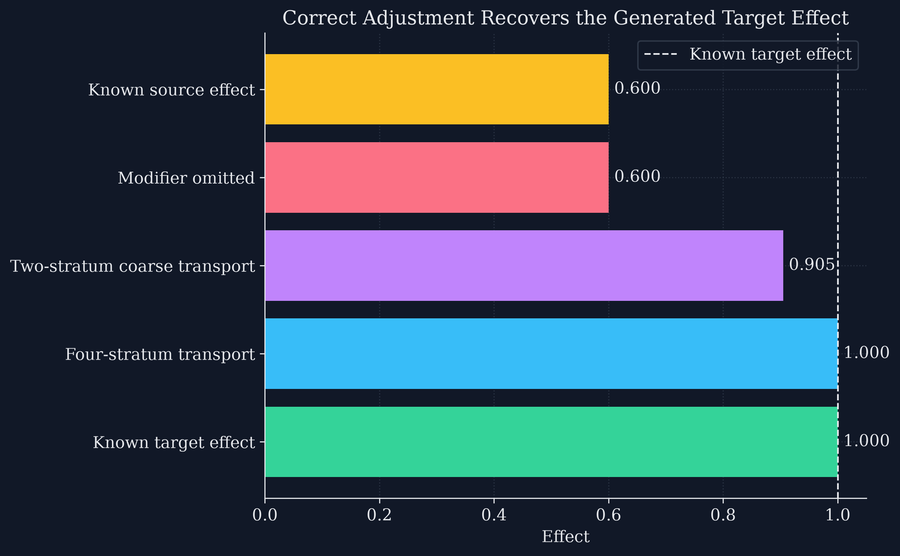

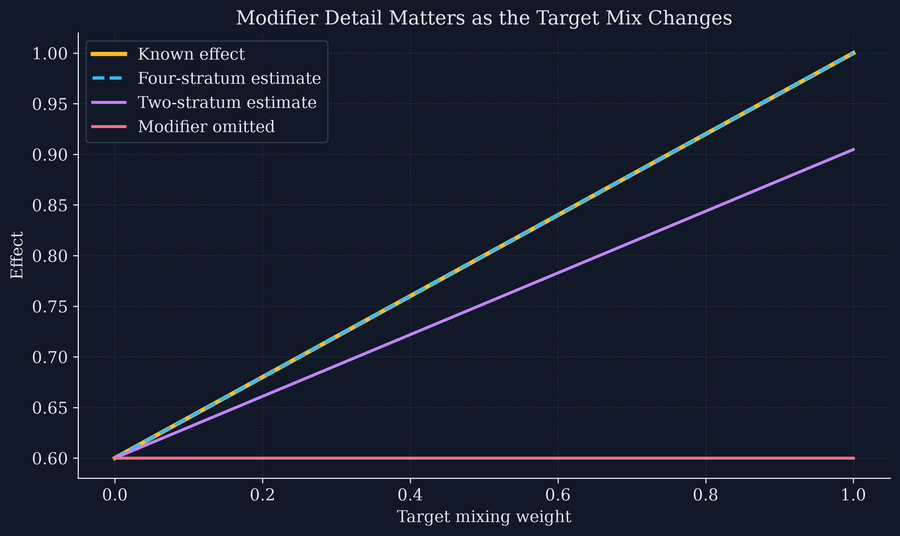

In [2]:
comparison.to_csv(FIGURE_DATA / "recovery_estimate_comparison.csv", index=False)
figure, axis = plt.subplots(figsize=(8.8, 5.4), constrained_layout=True)
colors = [PALETTE["green"], PALETTE["cyan"], PALETTE["violet"], PALETTE["rose"], PALETTE["amber"]]
bars = axis.barh(comparison["Calculation"], comparison["Estimate"], color=colors)
axis.axvline(known_target_effect, color=PALETTE["text"], linestyle="--", linewidth=1.2, label="Known target effect")
axis.set_xlabel("Effect")
axis.set_title("Correct Adjustment Recovers the Generated Target Effect")
axis.bar_label(bars, fmt="%.3f", padding=4, color=PALETTE["text"])
axis.legend()
finish_axis(axis)
save_figure(figure, "recovery_estimate_comparison")

mix_path.to_csv(FIGURE_DATA / "recovery_target_mix_path.csv", index=False)
figure, axis = plt.subplots(figsize=(8.8, 5.2), constrained_layout=True)
axis.plot(mix_path["Target mixing weight"], mix_path["Known effect"], color=PALETTE["amber"], linewidth=3, label="Known effect")
axis.plot(mix_path["Target mixing weight"], mix_path["Four-stratum estimate"], color=PALETTE["cyan"], linestyle="--", linewidth=2.3, label="Four-stratum estimate")
axis.plot(mix_path["Target mixing weight"], mix_path["Two-stratum estimate"], color=PALETTE["violet"], linewidth=2.1, label="Two-stratum estimate")
axis.plot(mix_path["Target mixing weight"], mix_path["Omitted-modifier estimate"], color=PALETTE["rose"], linewidth=2.1, label="Modifier omitted")
axis.set_xlabel("Target mixing weight")
axis.set_ylabel("Effect")
axis.set_title("Modifier Detail Matters as the Target Mix Changes")
axis.legend()
finish_axis(axis)
save_figure(figure, "recovery_target_mix_path")

## Detecting missing support during validation

For the generated four-stratum design, remove treated source support from the highest stratum while retaining positive target mass. The support condition fails because

$$
\pi_3^T>0\quad\text{and}\quad n_{1,3}^S=0.
$$

Here, stratum $3$ is target relevant, but its treated source count is zero. The calculation must stop rather than fill the missing conditional mean by extrapolation. If the target weight of stratum $3$ is changed to zero, the supported remaining strata can still be standardized.

### Generated support success and failure cases

In [3]:
missing_treated_counts = source_counts[1].to_numpy(dtype=float)
missing_treated_counts[-1] = 0
control_counts = source_counts[0].to_numpy(dtype=float)
support_failure = capture_failure(
    "Positive target mass with missing treated support",
    lambda: transported_ate(source_means[1], source_means[0], target_probabilities, missing_treated_counts, control_counts),
)

zero_high_weight = target_probabilities.copy()
zero_high_weight[-1] = 0
zero_high_weight = zero_high_weight / zero_high_weight.sum()
zero_high_value = transported_ate(source_means[1], source_means[0], zero_high_weight, missing_treated_counts, control_counts)

support_cases = pd.DataFrame([
    {"Case": "Complete four-stratum support", "Result": "Pass", "Value": transported, "Message": "Calculated"},
    {"Case": "Missing treated support with positive target mass", "Result": "Stop", "Value": np.nan, "Message": support_failure["Message"]},
    {"Case": "Missing treated support with zero target mass", "Result": "Pass", "Value": zero_high_value, "Message": "Unsupported stratum contributes zero"},
])
save_table(support_cases, "recovery_support_cases", "Generated support success and failure cases.", "tab:cim6-recovery-support-cases", fit=True)
support_cases_book = pd.DataFrame([
    {"Case": "Both source groups appear in every target stratum", "Result": "Calculated", "Value": transported},
    {"Case": "Treated source group is missing where the target has mass", "Result": "Stopped", "Value": np.nan},
    {"Case": "Treated source group is missing where target mass is zero", "Result": "Calculated", "Value": zero_high_value},
])
save_table(support_cases_book, "recovery_support_cases_book", "Plain-language generated support cases.", "tab:cim6-recovery-support-cases-book", fit=True);


,Case,Result,Value,Message
0,Complete four-stratum support,Pass,1,Calculated
1,Missing treated support with positive target mass,Stop,,Target-positive strata lack source treatment s...
2,Missing treated support with zero target mass,Pass,0.733333,Unsupported stratum contributes zero


,Case,Result,Value
0,Both source groups appear in every target stratum,Calculated,1
1,Treated source group is missing where the targ...,Stopped,
2,Treated source group is missing where target m...,Calculated,0.733333


### Generated-design input validation checks

In [3]:
assert support_failure["Rejected"]

invalid_checks = pd.DataFrame([
    capture_failure("Probabilities do not sum to one", lambda: transported_ate([1, 2], [0, 0], [0.4, 0.5], [1, 1], [1, 1])),
    capture_failure("Negative treated count", lambda: transported_ate([1], [0], [1], [-1], [1])),
    capture_failure("Mismatched mean arrays", lambda: transported_ate([1, 2], [0], [0.5, 0.5], [1, 1], [1, 1])),
    capture_failure("Nonfinite control mean", lambda: transported_ate([1, 2], [0, np.inf], [1, 0], [1, 0], [1, 0])),
])
save_table(invalid_checks, "recovery_invalid_input_checks", "Generated-design input validation checks.", "tab:cim6-recovery-invalid-inputs", fit=True)
invalid_checks_book = pd.DataFrame([
    {"Check": "Weights sum to one", "Result": "Stopped as required"},
    {"Check": "Source counts are nonnegative", "Result": "Stopped as required"},
    {"Check": "All mean lists have equal length", "Result": "Stopped as required"},
    {"Check": "All supplied means are finite", "Result": "Stopped as required"},
])
save_table(invalid_checks_book, "recovery_invalid_input_checks_book", "Plain-language generated-design input checks.", "tab:cim6-recovery-invalid-inputs-book");


,Check,Rejected,Message
0,Probabilities do not sum to one,Pass,target_probabilities must have nonnegative row...
1,Negative treated count,Pass,Stratum arrays must match with nonnegative sou...
2,Mismatched mean arrays,Pass,Stratum arrays must match with nonnegative sou...
3,Nonfinite control mean,Pass,control_means must contain finite values and c...


,Check,Result
0,Weights sum to one,Stopped as required
1,Source counts are nonnegative,Stopped as required
2,All mean lists have equal length,Stopped as required
3,All supplied means are finite,Stopped as required


### The Highest Target-Relevant Stratum Loses Treated Support

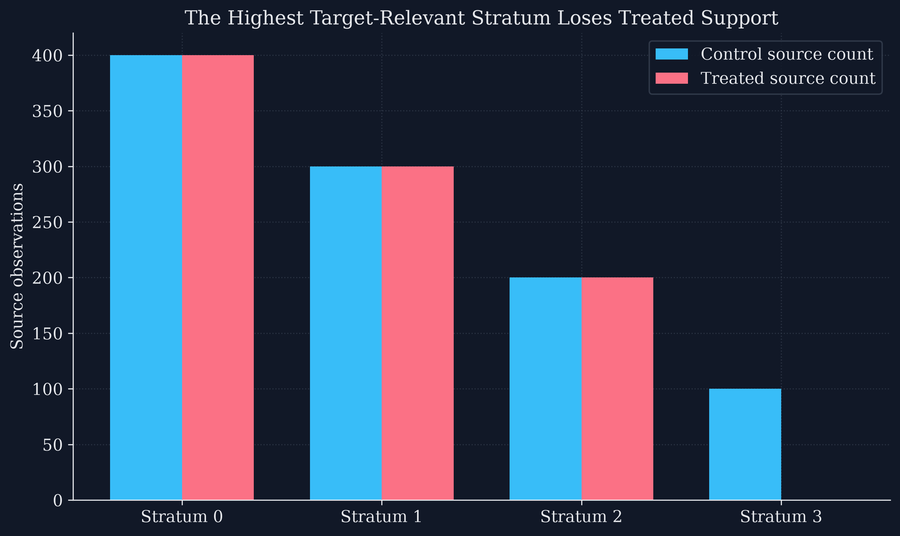

,Result,Value
0,Four-stratum recovery,Exact in the declared paired design
1,Two-stratum coarsening,Misses target truth because internal mixes differ
2,Modifier omitted,"Returns the source mixture, not the target mix..."
3,Missing target-positive support,Calculation stops explicitly
4,Generality,All numerical directions are local to the decl...


,Result,Value
0,Four-stratum recovery,Exact in the declared paired design
1,Two-stratum coarsening,Misses target truth because internal mixes differ
2,Modifier omitted,"Returns the source mixture, not the target mix..."
3,Missing target-positive support,Calculation stops explicitly
4,Generality,All numerical directions are local to the decl...


In [3]:
assert invalid_checks["Rejected"].all()

support_plot = pd.DataFrame({
    "Stratum": strata,
    "Control count": control_counts,
    "Treated count after removal": missing_treated_counts,
    "Target probability": target_probabilities,
})
support_plot.to_csv(FIGURE_DATA / "recovery_support_failure.csv", index=False)
positions = np.arange(len(strata))
figure, axis = plt.subplots(figsize=(8.8, 5.2), constrained_layout=True)
width = 0.36
axis.bar(positions - width / 2, support_plot["Control count"], width, color=PALETTE["cyan"], label="Control source count")
axis.bar(positions + width / 2, support_plot["Treated count after removal"], width, color=PALETTE["rose"], label="Treated source count")
axis.set_xticks(positions, [f"Stratum {value}" for value in strata])
axis.set_ylabel("Source observations")
axis.set_title("The Highest Target-Relevant Stratum Loses Treated Support")
axis.legend()
finish_axis(axis)
save_figure(figure, "recovery_support_failure")

recovery_summary = pd.DataFrame([
    {"Result": "Four-stratum recovery", "Value": "Exact in the declared paired design"},
    {"Result": "Two-stratum coarsening", "Value": "Misses target truth because internal mixes differ"},
    {"Result": "Modifier omitted", "Value": "Returns the source mixture, not the target mixture"},
    {"Result": "Missing target-positive support", "Value": "Calculation stops explicitly"},
    {"Result": "Generality", "Value": "All numerical directions are local to the declared design"},
])
save_table(recovery_summary, "recovery_section_summary", "Summary of generated recovery and failure results.", "tab:cim6-recovery-summary", fit=True)